# 01 — Numerical verification of the information-theoretic results

Companion to `04_mathematical_foundations.md`. Each section checks one result:
- discrete identities on random joint distributions (exact arithmetic up to floating point);
- the sufficiency propositions by brute force over every deterministic coarsening;
- the Gaussian–logistic examples with the exact quadrature in `scripts/gauss_logit.py`.

Seeds are fixed. All quantities are in nats.

In [1]:
import sys, itertools
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, '../scripts')
from gauss_logit import risk, three_quantities, mi_gauss, _sig
rng = np.random.default_rng(20261030)

def H(p):
    p = p[p > 0]
    return float(-(p * np.log(p)).sum())

def marg(P, axes, keep):
    # marginal of joint array P with axis labels `axes` (string) onto labels `keep`
    drop = tuple(i for i, a in enumerate(axes) if a not in keep)
    M = P.sum(axis=drop) if drop else P
    kept = ''.join(a for a in axes if a in keep)
    return np.einsum(kept + '->' + ''.join(sorted(keep, key=kept.index)), M) if kept else M

def Hs(P, axes, keep):
    return H(marg(P, axes, keep).ravel()) if keep else 0.0

def CMI(P, axes, X, Y, Z=''):
    # I(X;Y|Z) for label strings X, Y, Z
    return Hs(P, axes, X + Z) + Hs(P, axes, Y + Z) - Hs(P, axes, X + Y + Z) - Hs(P, axes, Z)

def rand_joint(*shape, conc=0.6):
    p = rng.gamma(conc, size=shape)
    return p / p.sum()

def coarsen(P, axes, src, dst, f, nz):
    # deterministic Z = f(src): returns joint with src replaced by dst (labels)
    i = axes.index(src)
    out = np.zeros(P.shape[:i] + (nz,) + P.shape[i + 1:])
    for s in range(P.shape[i]):
        idx = [slice(None)] * P.ndim; idx[i] = s
        oidx = [slice(None)] * P.ndim; oidx[i] = f[s]
        out[tuple(oidx)] += P[tuple(idx)]
    return out, axes.replace(src, dst)

def channel(P, axes, src, dst, Q):
    # stochastic Z | src with row-stochastic Q[s, z]: joint over (axes..., dst)
    i = axes.index(src)
    sub = axes + dst
    return np.einsum(f'{axes},{src}{dst}->{sub}', P, Q), sub
print('helpers ready')

helpers ready


## §1 Identity 1 — Bayes log-loss equals conditional entropy
For random p(y, v), E[−log P(Y|V)] equals H(Y|V), and any other predictor q does worse (Gibbs).

In [2]:
errs, gaps = [], []
for _ in range(200):
    P = rand_joint(3, 7)                         # axes 'yv'
    pv = P.sum(0); post = P / pv
    bayes = float(-(P * np.log(post)).sum())
    errs.append(abs(bayes - (H(P.ravel()) - H(pv))))
    q = rng.dirichlet(np.ones(3), size=7).T      # arbitrary conditional q(y|v)
    gaps.append(float(-(P * np.log(q)).sum()) - bayes)
print('max |E[-log P(Y|V)] - H(Y|V)| =', max(errs))
print('min excess loss of arbitrary q =', min(gaps), '(must be >= 0)')

max |E[-log P(Y|V)] - H(Y|V)| = 9.992007221626409e-16
min excess loss of arbitrary q = 0.15643495891166914 (must be >= 0)


## §2 Identity 2 — I(Y;A|S) = I(Y;A|X) + I(Y;X|S) − I(Y;X|S,A), for S = f(X)
Checked on 200 random p(y,a,x) with random coarsenings. Then a case where S is computed from (X, A), which breaks the Markov condition and the identity.

In [3]:
res = []
for _ in range(200):
    P = rand_joint(2, 3, 8)                      # 'yax'
    f = rng.integers(0, 4, size=8)
    J, ax = channel(P, 'yax', 'x', 's', np.eye(4)[f])   # deterministic S = f(X): joint 'yaxs'
    lhs = CMI(J, ax, 'y', 'a', 's')
    rhs = CMI(J, ax, 'y', 'a', 'x') + CMI(J, ax, 'y', 'x', 's') - CMI(J, ax, 'y', 'x', 'sa')
    res.append(abs(lhs - rhs))
print('Markov case: max |LHS-RHS| =', max(res))
# violation: S = g(X, A)
P = rand_joint(2, 3, 8)
g = rng.integers(0, 4, size=(8, 3))
J = np.zeros((2, 3, 8, 4))
for x in range(8):
    for a in range(3):
        J[:, a, x, g[x, a]] += P[:, a, x]
lhs = CMI(J, 'yaxs', 'y', 'a', 's')
rhs = CMI(J, 'yaxs', 'y', 'a', 'x') + CMI(J, 'yaxs', 'y', 'x', 's') - CMI(J, 'yaxs', 'y', 'x', 'sa')
print('S = g(X, A) (Markov violated): LHS-RHS =', lhs - rhs, '(nonzero expected)')

Markov case: max |LHS-RHS| = 1.3322676295501878e-15
S = g(X, A) (Markov violated): LHS-RHS = -0.03607809173300902 (nonzero expected)


## §3 Identity 3 — M_A = C_Y − L_YA, ceiling M_A ≤ C_Y, efficiency η
Checked for deterministic coarsenings Z = f(S) and stochastic channels Z ~ q(·|S) with noise independent of (Y, A).

max |M - (C - L)|            = 8.881784197001252e-16
max |C - I(Y;S|Z)|           = 1.3322676295501878e-15
max |L - I(Y;S|Z,A)|         = 2.220446049250313e-15
max (M - C)  [ceiling, <= 0] = -0.02456582977537214
share with M < 0 (synergy)   = 0.981


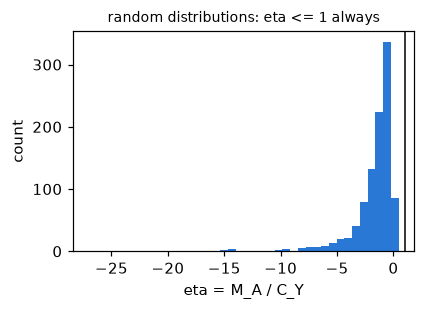

In [4]:
rows = []
for kind in ['deterministic', 'stochastic']:
    for _ in range(500):
        P = rand_joint(2, 3, 8)                  # 'yas'
        if kind == 'deterministic':
            Q = np.eye(4)[rng.integers(0, 4, size=8)]
        else:
            Q = rng.dirichlet(np.ones(4) * 0.5, size=8)
        J, ax = channel(P, 'yas', 's', 'z', Q)   # 'yasz'
        CY = Hs(J, ax, 'yz') - Hs(J, ax, 'z') - (Hs(J, ax, 'ys') - Hs(J, ax, 's'))
        LYA = Hs(J, ax, 'yza') - Hs(J, ax, 'za') - (Hs(J, ax, 'ysa') - Hs(J, ax, 'sa'))
        MA = CMI(J, ax, 'y', 'a', 'z') - CMI(J, ax, 'y', 'a', 's')
        rows.append((kind, CY, LYA, MA, CMI(J, ax, 'y', 's', 'z'), CMI(J, ax, 'y', 's', 'za')))
R = np.array([r[1:] for r in rows])
print('max |M - (C - L)|            =', np.abs(R[:, 2] - (R[:, 0] - R[:, 1])).max())
print('max |C - I(Y;S|Z)|           =', np.abs(R[:, 0] - R[:, 3]).max())
print('max |L - I(Y;S|Z,A)|         =', np.abs(R[:, 1] - R[:, 4]).max())
print('max (M - C)  [ceiling, <= 0] =', (R[:, 2] - R[:, 0]).max())
print('share with M < 0 (synergy)   =', (R[:, 2] < -1e-12).mean())
eta = R[:, 2] / R[:, 0]
eta = eta[R[:, 0] > 1e-6]
plt.figure(figsize=(4, 2.6)); plt.hist(eta, bins=40, color='#2a78d6')
plt.axvline(1, color='k', lw=1); plt.xlabel('eta = M_A / C_Y'); plt.ylabel('count')
plt.title('random distributions: eta <= 1 always', fontsize=9)

**Equality case.** Merge only S-cells that share P(Y | S, A = a) for every a. Then fused sufficiency holds (L = 0), M = C exactly, while C > 0.

In [5]:
# S = (sA, sY), A affects Y; sA is a noisy copy of A carrying no extra Y information
pA = np.array([0.3, 0.4, 0.3]); pSY = np.array([0.5, 0.5])
noise = np.array([[0.8, 0.15, 0.05], [0.1, 0.8, 0.1], [0.05, 0.15, 0.8]])  # P(sA | A)
logit = lambda a, sy: -1.0 + 1.2 * a + 1.5 * sy
J = np.zeros((2, 3, 3, 2))                       # 'yabc' with b = sA, c = sY
for a in range(3):
    for sa in range(3):
        for sy in range(2):
            p1 = _sig(logit(a, sy)); w = pA[a] * noise[a, sa] * pSY[sy]
            J[1, a, sa, sy] += w * p1; J[0, a, sa, sy] += w * (1 - p1)
Js = J.reshape(2, 3, 6)                          # S = (sA, sY) flattened, 'yas'
f = np.array([sy for sa in range(3) for sy in range(2)])   # Z = sY (erase sA)
Jz, ax = channel(Js, 'yas', 's', 'z', np.eye(2)[f])
CY = CMI(Jz, ax, 'y', 's', 'z'); LYA = CMI(Jz, ax, 'y', 's', 'za')
MA = CMI(Jz, ax, 'y', 'a', 'z') - CMI(Jz, ax, 'y', 'a', 's')
print(f'C_Y = {CY:.6f}, L_YA = {LYA:.2e}, M_A = {MA:.6f}, eta = {MA/CY:.6f}')

C_Y = 0.040551, L_YA = -4.44e-16, M_A = 0.040551, eta = 1.000000


## §4 Restricted predictor families
(a) Linear T with logistic heads: the ceiling holds (Proposition 1). Each case is checked with large-sample fits.
(b) Nonlinear T with linear heads: the ceiling can fail (XOR).
(c) An invertible dose (D1) changes nothing at population level, yet a regularised head's measured Δ moves.

In [6]:
from sklearn.linear_model import LogisticRegression
def fit_risk(V, y, Vt, yt, C=1e4):
    m = LogisticRegression(C=C, max_iter=5000).fit(V, y)
    p = np.clip(m.predict_proba(Vt)[:, 1], 1e-12, 1 - 1e-12)
    return float(-(yt * np.log(p) + (1 - yt) * np.log(1 - p)).mean())
# (a) linear T: random rank-reducing projections of S, A observed
n = 200_000
viol = []
for rep in range(8):
    m = 6; Q = rng.standard_normal((m, m)); Sig = Q @ Q.T / m + 0.5 * np.eye(m)
    F = rng.multivariate_normal(np.zeros(m), Sig, size=2 * n); w = rng.standard_normal(m)
    y = (rng.random(2 * n) < _sig(-0.5 + F @ w)).astype(int)
    A = F[:, :1]; S = F[:, 1:]                    # A = first latent; S sees the rest (correlated with A)
    T = np.linalg.qr(rng.standard_normal((5, 5)))[0][:, :3]     # keep 3 of 5 directions
    tr, te = slice(0, n), slice(n, 2 * n)
    RS, RZ = fit_risk(S[tr], y[tr], S[te], y[te]), fit_risk(S[tr] @ T, y[tr], S[te] @ T, y[te])
    RSA = fit_risk(np.c_[S[tr], A[tr]], y[tr], np.c_[S[te], A[te]], y[te])
    RZA = fit_risk(np.c_[S[tr] @ T, A[tr]], y[tr], np.c_[S[te] @ T, A[te]], y[te])
    Cl, Ml = RZ - RS, (RZ - RZA) - (RS - RSA)
    viol.append(Ml - Cl)
print('(a) linear T, logistic heads: max (M - C) over 8 models =', max(viol), '(<= ~0 up to sampling error)')
# (b) XOR: Y = 1{s1*s2 > 0}, A independent noise; T(S) = s1*s2
n = 100_000
S = rng.standard_normal((2 * n, 2)); A = rng.standard_normal((2 * n, 1))
y = ((S[:, 0] * S[:, 1] > 0) ^ (rng.random(2 * n) < 0.1)).astype(int)
Z = (S[:, 0] * S[:, 1])[:, None]
tr, te = slice(0, n), slice(n, 2 * n)
RS, RZ = fit_risk(S[tr], y[tr], S[te], y[te]), fit_risk(Z[tr], y[tr], Z[te], y[te])
RSA, RZA = fit_risk(np.c_[S[tr], A[tr]], y[tr], np.c_[S[te], A[te]], y[te]), fit_risk(np.c_[Z[tr], A[tr]], y[tr], np.c_[Z[te], A[te]], y[te])
Cl, Ml = RZ - RS, (RZ - RZA) - (RS - RSA)
print(f'(b) nonlinear T, linear heads: C^lin = {Cl:.4f} (< 0: T made Y linearly accessible), M^lin = {Ml:.5f} > C^lin')
# (c) D1 dose: S = (sA, sY), sA = A + noise; regularised logistic (C = 0.01) on (1-t) * sA
n = 50_000
Aa = rng.standard_normal(2 * n); sA = Aa + 0.3 * rng.standard_normal(2 * n); sY = rng.standard_normal(2 * n)
y = (rng.random(2 * n) < _sig(-1 + 1.0 * Aa + 1.0 * sY)).astype(int)
tr, te = slice(0, n), slice(n, 2 * n)
for t in [0, 0.5, 0.9, 0.99]:
    Sx = np.c_[(1 - t) * sA, sY]
    d = fit_risk(Sx[tr], y[tr], Sx[te], y[te], C=0.01) - fit_risk(np.c_[Sx[tr], Aa[tr]], y[tr], np.c_[Sx[te], Aa[te]], y[te], C=0.01)
    print(f'(c) D1 t={t:4}: measured Delta_A (C=0.01) = {1e3*d:7.3f} x1e-3 nats  [population Delta_A unchanged for t<1]')

(a) linear T, logistic heads: max (M - C) over 8 models = -0.006765893388332722 (<= ~0 up to sampling error)
(b) nonlinear T, linear heads: C^lin = -0.2040 (< 0: T made Y linearly accessible), M^lin = -0.00000 > C^lin
(c) D1 t=   0: measured Delta_A (C=0.01) =   6.074 x1e-3 nats  [population Delta_A unchanged for t<1]
(c) D1 t= 0.5: measured Delta_A (C=0.01) =   6.332 x1e-3 nats  [population Delta_A unchanged for t<1]
(c) D1 t= 0.9: measured Delta_A (C=0.01) =  25.773 x1e-3 nats  [population Delta_A unchanged for t<1]
(c) D1 t=0.99: measured Delta_A (C=0.01) =  73.676 x1e-3 nats  [population Delta_A unchanged for t<1]


## §5 Conditional independence statements are not interchangeable
Each case below is a constructed discrete distribution.

In [7]:
def show(name, J, ax, pairs):
    print(name, {k: round(CMI(J, ax, *v), 6) for k, v in pairs.items()})
# (i) Y ⟂ A | X but not | S: X = (A-proxy bit, signal), Y depends on X only; S drops the proxy bit
J = np.zeros((2, 2, 4))                       # 'yax'; x = 2*b + c, b = A copy (noisy), c signal
for a in range(2):
    for b in range(2):
        for c in range(2):
            pb = 0.9 if b == a else 0.1; p1 = _sig(-1 + 2 * b + 1.5 * c)
            J[1, a, 2 * b + c] += 0.5 * pb * 0.5 * p1; J[0, a, 2 * b + c] += 0.5 * pb * 0.5 * (1 - p1)
Js, ax = channel(J, 'yax', 'x', 's', np.eye(2)[[0, 1, 0, 1]])   # S = c only
show('(i) ', Js, ax, {'I(Y;A|X)': ('y', 'a', 'x'), 'I(Y;A|S)': ('y', 'a', 's')})
# (ii) Y ⟂ A | S but not | Z: take S := the full 4-state X above and Z := signal bit only
J2, ax2 = channel(J, 'yax', 'x', 'z', np.eye(2)[[0, 1, 0, 1]])
J2 = J2.transpose(0, 1, 2, 3); show('(ii) ', J2, 'yaxz', {'I(Y;A|S=X)': ('y', 'a', 'x'), 'I(Y;A|Z)': ('y', 'a', 'z')})
# (iii) Y ⟂ A | Z but not | S (synergy): Y = S1 xor A, Z drops S1
J = np.zeros((2, 2, 2))                       # 'yas'
for a in range(2):
    for s in range(2):
        J[s ^ a, a, s] += 0.25
Jz, ax = channel(J, 'yas', 's', 'z', np.ones((2, 1)))
show('(iii)', Jz, ax, {'I(Y;A|S)': ('y', 'a', 's'), 'I(Y;A|Z)': ('y', 'a', 'z')})
print('-> processing can raise (i) or lower (iii) I(Y;A|.): no data-processing inequality for conditional MI')

(i)  {'I(Y;A|X)': 0.0, 'I(Y;A|S)': 0.056639}
(ii)  {'I(Y;A|S=X)': 0.0, 'I(Y;A|Z)': 0.056639}
(iii) {'I(Y;A|S)': 0.693147, 'I(Y;A|Z)': 0.0}
-> processing can raise (i) or lower (iii) I(Y;A|.): no data-processing inequality for conditional MI


## §6 Propositions 2–3 — minimum leakage under image-only vs fused preservation
Brute force over all 203 set partitions of a 6-state S (every deterministic Z = f(S) up to relabelling). The answers are compared with I(A; m(S)) and I(A; 𝔐(S)).

In [8]:
def partitions(seq):
    if not seq:
        yield []; return
    first, rest = seq[0], seq[1:]
    for smaller in partitions(rest):
        for i in range(len(smaller)):
            yield smaller[:i] + [[first] + smaller[i]] + smaller[i + 1:]
        yield [[first]] + smaller
def evaluate(Js):
    out = []
    for part in partitions(list(range(6))):
        f = np.zeros(6, int)
        for k, block in enumerate(part):
            f[block] = k
        Jz, ax = channel(Js, 'yas', 's', 'z', np.eye(len(part))[f])
        out.append((CMI(Jz, ax, 'y', 's', 'z'), CMI(Jz, ax, 'y', 's', 'za'), CMI(Jz, ax, 'a', 'z'), part))
    return out
def group_by(keyfun):
    groups = {}
    for s in range(6):
        groups.setdefault(keyfun(s), []).append(s)
    f = np.zeros(6, int)
    for k, g in enumerate(groups.values()):
        f[g] = k
    return f, len(groups)
def check(Js, label):
    out = evaluate(Js)
    tol = 1e-10
    minC = min(r[2] for r in out if r[0] < tol)
    minL = min(r[2] for r in out if r[1] < tol)
    pys = Js.sum(1); post = np.round(pys / pys.sum(0), 10)                 # m(S)
    pyas = np.round(Js / Js.sum(0, keepdims=True), 10)                    # P(Y|a,s)
    fm, km = group_by(lambda s: tuple(post[:, s]))
    fM, kM = group_by(lambda s: tuple(pyas[:, :, s].ravel()))
    Jm, ax = channel(Js, 'yas', 's', 'z', np.eye(km)[fm]); JM, axM = channel(Js, 'yas', 's', 'z', np.eye(kM)[fM])
    print(f'{label}: min I(A;Z) s.t. C=0: {minC:.6f}  vs I(A;m(S)) = {CMI(Jm, ax, "a", "z"):.6f} | '
          f'min s.t. L=0: {minL:.6f}  vs I(A;M(S)) = {CMI(JM, axM, "a", "z"):.6f}')
# structured case (Corollary 5): S = (sA in 3, sY in 2), sA noisy copy of A (positivity holds), Y <- (A, sY)
Js = J0 = None
pA = np.array([0.3, 0.4, 0.3]); noise = np.array([[0.7, 0.2, 0.1], [0.15, 0.7, 0.15], [0.1, 0.2, 0.7]])
Js = np.zeros((2, 3, 6))
for a in range(3):
    for sa in range(3):
        for sy in range(2):
            p1 = _sig(-1 + 1.2 * a + 1.5 * sy); w = pA[a] * noise[a, sa] * 0.5
            Js[1, a, 2 * sa + sy] += w * p1; Js[0, a, 2 * sa + sy] += w * (1 - p1)
check(Js, 'Cor. 5 example')
# random structured cases: P(Y|S,A) depends on (g(S), A) for random g; P(A|S) random with full support
for rep in range(5):
    g = rng.integers(0, 3, size=6); pS = rng.dirichlet(np.ones(6)); pAS = rng.dirichlet(np.ones(3), size=6)
    tab = rng.uniform(0.05, 0.95, size=(3, 3))           # P(Y=1 | g, a)
    Js = np.zeros((2, 3, 6))
    for s in range(6):
        for a in range(3):
            w = pS[s] * pAS[s, a]; Js[1, a, s] += w * tab[g[s], a]; Js[0, a, s] += w * (1 - tab[g[s], a])
    check(Js, f'random g #{rep}')
# positivity violated: A determined by S for some states -> min under L=0 can drop below I(A; M(S))
pAS = np.array([[1, 0, 0], [1, 0, 0], [0, 1, 0], [0, 1, 0], [0, 0, 1], [0, 0, 1]], float)
tab = rng.uniform(0.05, 0.95, size=(6, 3))
Js = np.zeros((2, 3, 6))
for s in range(6):
    for a in range(3):
        w = pAS[s, a] / 6; Js[1, a, s] += w * tab[s, a]; Js[0, a, s] += w * (1 - tab[s, a])
check(Js, 'positivity violated')

Cor. 5 example: min I(A;Z) s.t. C=0: 0.280285  vs I(A;m(S)) = 0.280285 | min s.t. L=0: 0.000000  vs I(A;M(S)) = 0.000000
random g #0: min I(A;Z) s.t. C=0: 0.123542  vs I(A;m(S)) = 0.123542 | min s.t. L=0: 0.041730  vs I(A;M(S)) = 0.041730
random g #1: min I(A;Z) s.t. C=0: 0.082203  vs I(A;m(S)) = 0.082203 | min s.t. L=0: 0.035723  vs I(A;M(S)) = 0.035723
random g #2: min I(A;Z) s.t. C=0: 0.230441  vs I(A;m(S)) = 0.230441 | min s.t. L=0: 0.013808  vs I(A;M(S)) = 0.013808
random g #3: min I(A;Z) s.t. C=0: 0.228554  vs I(A;m(S)) = 0.228554 | min s.t. L=0: 0.120432  vs I(A;M(S)) = 0.120432
random g #4: min I(A;Z) s.t. C=0: 0.188747  vs I(A;m(S)) = 0.188747 | min s.t. L=0: 0.139957  vs I(A;M(S)) = 0.139957
positivity violated: min I(A;Z) s.t. C=0: 1.098612  vs I(A;m(S)) = 1.098612 | min s.t. L=0: 0.000000  vs I(A;M(S)) = 1.098612


## §7 Gaussian–logistic examples (exact quadrature)
Latents F = (A, U, G, N_A, N_Y). Image S = (S_A, S_Y) with S_A = A + σ_u U + N_A and S_Y = G + N_Y. The logit is β_A A + β_U U + β_G G. Erasure removes S_A. "Oracle" is the attribute-conditional positive control.

E1 redundant age                       C_Y=   60.45 M_A=   60.45 L_YA=   0.00 eta=1.000 I(A;S)=0.746 I(A;Z)=-0.000  (x1e-3 nats)
E2 entangled (beta_U=0.8)              C_Y=  107.53 M_A=   65.32 L_YA=  42.21 eta=0.607 I(A;S)=0.746 I(A;Z)=-0.000  (x1e-3 nats)
E3 irrelevant age                      C_Y=    0.00 M_A=    0.00 L_YA=   0.00 eta=nan I(A;S)=0.746 I(A;Z)=-0.000  (x1e-3 nats)
E6 shared component (corr A,G=0.6)     C_Y=    0.25 M_A=    0.25 L_YA=  -0.00 eta=1.000 I(A;S)=0.799 I(A;Z)=0.200  (x1e-3 nats)
E7 strong age-label                    C_Y=  199.04 M_A=  199.04 L_YA=  -0.00 eta=1.000 I(A;S)=0.746 I(A;Z)=-0.000  (x1e-3 nats)
E2 eta vs beta_U: [1.    0.989 0.96  0.917 0.865 0.807 0.743 0.677 0.607 0.537 0.465 0.393
 0.32  0.247 0.174 0.102]
E6 eta vs corr(A,G) (orthogonal removal of Cov(S,A)): [0.804 0.804 0.805 0.806 0.808 0.81  0.813 0.817 0.822 0.829 0.838 0.85
 0.866 0.888 0.919 0.965]


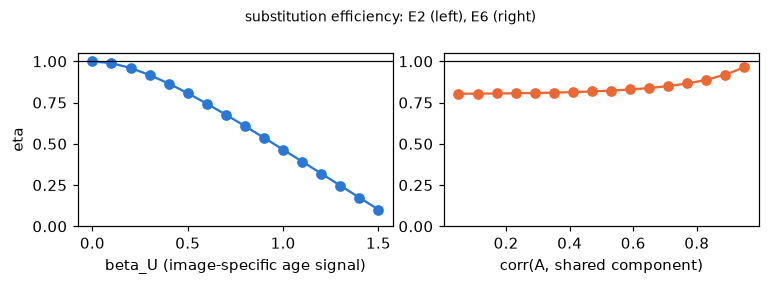

In [9]:
def build(beta_A=1.0, beta_U=0.0, beta_G=1.0, sig_u=0.5, corrAG=0.0, nA=0.2, nY=0.3):
    # latent order: A, U, G, NA, NY
    Sig = np.eye(5); Sig[0, 2] = Sig[2, 0] = corrAG; Sig[3, 3] = nA ** 2; Sig[4, 4] = nY ** 2
    KS = np.array([[1, sig_u, 0, 1, 0], [0, 0, 1, 0, 1]], float)      # S_A, S_Y
    a = np.array([1, 0, 0, 0, 0], float)
    w = np.array([beta_A, beta_U, beta_G, 0, 0], float)
    return Sig, w, KS, a
def erase_SA(KS):
    return KS[1:2]                                                     # Z = S_Y
for name, kw in [('E1 redundant age', dict(beta_U=0.0)), ('E2 entangled (beta_U=0.8)', dict(beta_U=0.8)),
                 ('E3 irrelevant age', dict(beta_A=0.0, beta_U=0.0)), ('E6 shared component (corr A,G=0.6)', dict(beta_A=0.0, corrAG=0.6)),
                 ('E7 strong age-label', dict(beta_A=2.5, beta_G=0.5))]:
    Sig, w, KS, a = build(**kw)
    q = three_quantities(Sig, w, -0.5, KS, erase_SA(KS), a)
    print(f"{name:38s} C_Y={1e3*q['C_Y']:8.2f} M_A={1e3*q['M_A']:8.2f} L_YA={1e3*q['L_YA']:7.2f} eta={q['eta']:.3f} "
          f"I(A;S)={q['I_A_S']:.3f} I(A;Z)={q['I_A_Z']:.3f}  (x1e-3 nats)")
# eta as a function of the image-specific age weight beta_U (E2) and of corr(A, G) (E6)
bu = np.linspace(0, 1.5, 16); et = [three_quantities(*build(beta_U=b)[:2], -0.5, build(beta_U=b)[2], erase_SA(build(beta_U=b)[2]), build()[3])['eta'] for b in bu]
cg = np.linspace(0.05, 0.95, 16)
def e6(c):
    Sig, w, KS, a = build(beta_A=0.0, corrAG=c)
    # in E6 the age-predictive direction is S_Y (via G) as well; erase LEACE-style the cross-covariance direction
    Ss = KS @ Sig @ KS.T; sa = KS @ Sig @ a
    W = np.linalg.inv(np.linalg.cholesky(Ss)).T @ np.linalg.inv(np.linalg.cholesky(Ss)) if False else None
    u = sa / np.linalg.norm(sa); P = np.eye(2) - np.outer(u, u)   # orthogonal removal of Cov(S, A)
    return three_quantities(Sig, w, -0.5, KS, P @ KS, a)['eta']
eg = [e6(c) for c in cg]
print('E2 eta vs beta_U:', np.round(et, 3)); print('E6 eta vs corr(A,G) (orthogonal removal of Cov(S,A)):', np.round(eg, 3))
fig, axs = plt.subplots(1, 2, figsize=(7, 2.6))
axs[0].plot(bu, et, 'o-', color='#2a78d6'); axs[0].set_xlabel('beta_U (image-specific age signal)'); axs[0].set_ylabel('eta'); axs[0].set_ylim(0, 1.05)
axs[1].plot(cg, eg, 'o-', color='#eb6834'); axs[1].set_xlabel('corr(A, shared component)'); axs[1].set_ylim(0, 1.05)
for ax_ in axs: ax_.axhline(1, color='k', lw=0.8)
fig.suptitle('substitution efficiency: E2 (left), E6 (right)', fontsize=9); plt.tight_layout()

**Positive control: the attribute-conditional (oracle) residual.** Z = S − E[S|A] used together with A. This breaks the Markov condition, and gives L = 0, η = 1 even in the entangled case E2. **LEACE vs orthogonal removal:** both zero Cov(Z, A); compare the diagnostic information each keeps.

In [10]:
Sig, w, KS, a = build(beta_U=0.8)
# oracle residual: rows of the view that the fused model sees = (S - Cov(S,A)/Var(A) * A, A)  -> same span as (S, A)
coef = (KS @ Sig @ a) / (a @ Sig @ a)
KZo = KS - np.outer(coef, a)
RS, RSA = risk(Sig, w, -0.5, KS), risk(Sig, w, -0.5, np.vstack([KS, a]))
RZo, RZoA = risk(Sig, w, -0.5, KZo), risk(Sig, w, -0.5, np.vstack([KZo, a]))
C_, L_ = RZo - RS, RZoA - RSA
print(f'oracle residual (E2): C_Y={1e3*C_:.2f}, L_YA={1e3*L_:.2e}, eta={(C_ - L_)/C_:.6f}  -> perfect substitution by construction')
# LEACE (oblique, whitened) vs orthogonal removal, with S correlated across components
Sig, w, KS, a = build(beta_U=0.3, corrAG=0.4)
Ss = KS @ Sig @ KS.T; sa = KS @ Sig @ a
lam, V = np.linalg.eigh(Ss); Wh = V @ np.diag(lam ** -0.5) @ V.T; Wp = V @ np.diag(lam ** 0.5) @ V.T
u = Wh @ sa; u = u / np.linalg.norm(u)
P_leace = np.eye(2) - Wp @ np.outer(u, u) @ Wh
v = sa / np.linalg.norm(sa); P_orth = np.eye(2) - np.outer(v, v)
for nm, P in [('LEACE', P_leace), ('orthogonal (RLACE closed form)', P_orth)]:
    q = three_quantities(Sig, w, -0.5, KS, P @ KS, a)
    print(f"{nm:32s} Cov(Z,A)={float((P @ KS) @ Sig @ a @ np.ones(1)) if False else np.round(P @ sa, 12)} "
          f"C_Y={1e3*q['C_Y']:.2f} M_A={1e3*q['M_A']:.2f} L_YA={1e3*q['L_YA']:.2f} eta={q['eta']:.3f} I(A;Z)={q['I_A_Z']:.3f}")

oracle residual (E2): C_Y=71.27, L_YA=-1.11e-13, eta=1.000000  -> perfect substitution by construction
LEACE                            Cov(Z,A)=[0. 0.] C_Y=141.95 M_A=125.29 L_YA=16.65 eta=0.883 I(A;Z)=-0.000
orthogonal (RLACE closed form)   Cov(Z,A)=[0. 0.] C_Y=141.95 M_A=125.29 L_YA=16.65 eta=0.883 I(A;Z)=-0.000


**E4 nonlinear encoding.** S_A = A² − 1 has zero covariance with A, so LEACE is a no-op. A linear probe finds no age, while a nonlinear probe recovers |A|.

In [11]:
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import Ridge
n = 40_000
Aa = rng.standard_normal(2 * n); sA = Aa ** 2 - 1 + 0.1 * rng.standard_normal(2 * n); sY = rng.standard_normal(2 * n)
S = np.c_[sA, sY]
print('Cov(S_A, A) =', round(float(np.cov(sA, Aa)[0, 1]), 4), '-> LEACE fitted on (S, A) removes ~nothing')
tr, te = slice(0, n), slice(n, 2 * n)
r2 = lambda p, t: 1 - ((t - p) ** 2).mean() / t.var()
lin = Ridge(1.0).fit(S[tr], Aa[tr]); mlp = MLPRegressor(hidden_layer_sizes=(64,), max_iter=300, random_state=0).fit(S[tr], np.abs(Aa[tr]))
print('linear probe R^2 for A   =', round(r2(lin.predict(S[te]), Aa[te]), 4))
print('MLP probe R^2 for |A|    =', round(r2(mlp.predict(S[te]), np.abs(Aa[te])), 4))

Cov(S_A, A) = -0.0187 -> LEACE fitted on (S, A) removes ~nothing
linear probe R^2 for A   = 0.0001
MLP probe R^2 for |A|    = 0.9752


**E5 synergy.** Y = S₁ ⊕ A (with noise): erasing S₁ has C_Y ≈ 0, yet M_A < 0.

In [12]:
J = np.zeros((2, 2, 2))        # 'yas'
for a in range(2):
    for s in range(2):
        J[s ^ a, a, s] += 0.25 * 0.9; J[1 - (s ^ a), a, s] += 0.25 * 0.1
Jz, ax = channel(J, 'yas', 's', 'z', np.ones((2, 1)))
CY = CMI(Jz, ax, 'y', 's', 'z'); LYA = CMI(Jz, ax, 'y', 's', 'za'); MA = CMI(Jz, ax, 'y', 'a', 'z') - CMI(Jz, ax, 'y', 'a', 's')
print(f'C_Y = {CY:.6f}, L_YA = {LYA:.6f}, M_A = {MA:.6f}  (M_A = C - L < 0)')

C_Y = 0.000000, L_YA = 0.368064, M_A = -0.368064  (M_A = C - L < 0)


## §8 Proposition 4 — linear erasers with the same kernel are information-equivalent
LEACE (oblique), the RLACE/OLS closed form (orthogonal) and an arbitrary oblique projection with kernel colsp(Σ_SA) give identical Bayes risks. They differ only in distortion E‖Z − S‖². Checked on random 12-dimensional Gaussian–logistic models with a vector attribute.

In [13]:
diffs, dist = [], []
for rep in range(50):
    m, d, k = 16, 12, 2
    Q = rng.standard_normal((m, m)); Sig = Q @ Q.T / m + 0.2 * np.eye(m)
    KS = rng.standard_normal((d, m)); Ka = rng.standard_normal((k, m)); w = rng.standard_normal(m)
    Ss = KS @ Sig @ KS.T; Sa = KS @ Sig @ Ka.T                     # Cov(S), Cov(S, A)
    lam, V = np.linalg.eigh(Ss); Wh = V @ np.diag(lam ** -0.5) @ V.T; Wp = V @ np.diag(lam ** 0.5) @ V.T
    U = np.linalg.qr(Wh @ Sa)[0]; P1 = np.eye(d) - Wp @ U @ U.T @ Wh                # LEACE
    Uo = np.linalg.qr(Sa)[0]; P2 = np.eye(d) - Uo @ Uo.T                            # orthogonal
    B = rng.standard_normal((d, k)); P3 = np.eye(d) - Uo @ np.linalg.solve(B.T @ Uo, B.T)   # random oblique, same kernel
    r = [risk(Sig, w, 0.3, P @ KS) for P in (P1, P2, P3)]
    ra = [risk(Sig, w, 0.3, np.vstack([P @ KS, Ka])) for P in (P1, P2, P3)]
    diffs.append(max(np.ptp(r), np.ptp(ra)))
    dist.append([np.trace((np.eye(d) - P) @ Ss @ (np.eye(d) - P).T) for P in (P1, P2, P3)])
    assert np.allclose(P1 @ Sa, 0) and np.allclose(P2 @ Sa, 0) and np.allclose(P3 @ Sa, 0)
dist = np.array(dist)
print('max spread of R(Z), R(Z,A) across the three erasers:', max(diffs))
print('distortion E||Z-S||^2: LEACE <= orthogonal in', np.mean(dist[:, 0] <= dist[:, 1] + 1e-9) * 100, '% of models;',
      'LEACE <= random oblique in', np.mean(dist[:, 0] <= dist[:, 2] + 1e-9) * 100, '%')

max spread of R(Z), R(Z,A) across the three erasers: 3.8535841184739184e-13
distortion E||Z-S||^2: LEACE <= orthogonal in 100.0 % of models; LEACE <= random oblique in 100.0 %
